# 02 · Modelagem de tópicos

Descobre os temas das teses e dissertações sem rótulos prévios, com dois métodos:

- **BERTopic**, o método principal: agrupa resumos pelo *sentido* (embeddings) e depois descreve
  cada grupo pelas palavras mais características.
- **LDA**, o baseline clássico: trata cada resumo como uma mistura de tópicos e cada tópico
  como uma distribuição de palavras, só a partir da contagem de palavras.

No fim, os dois são comparados por **coerência** e **diversidade** dos tópicos.

Antes de rodar: `python src/preprocess.py` e `python src/embeddings.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

sys.path.append("../src")
from topic_metrics import coerencia_npmi, diversidade

PROCESSADOS = Path("../data/processed")
FIGURAS = Path("../reports/figures")
RELATORIOS = Path("../reports")

SEMENTE = 42  # fixa a aleatoriedade do UMAP e do LDA para o resultado ser reproduzível

# Só as colunas usadas aqui: o resumo completo e o texto limpo ocupam muita memória à toa
base = pd.read_csv(PROCESSADOS / "resumos_preprocessados.csv.gz",
                   usecols=["ano", "grau", "regiao", "texto_lematizado"])
arquivo = np.load(PROCESSADOS / "embeddings.npz")
ids, embeddings = arquivo["ids"], arquivo["vetores"]

docs = base.loc[ids].copy()
docs["id"] = ids
del base  # libera memória: daqui em diante só usamos os resumos aptos
print(f"{len(docs)} resumos, embeddings de {embeddings.shape[1]} dimensões")

23007 resumos, embeddings de 384 dimensões


## BERTopic

O BERTopic funciona em quatro passos:

1. **Embeddings** (já calculados): cada resumo vira um vetor que representa seu sentido.
2. **UMAP**: reduz os vetores de 384 para 5 dimensões, mantendo resumos parecidos próximos.
   Agrupar em 384 dimensões funciona mal (a "maldição da dimensionalidade").
3. **HDBSCAN**: encontra grupos densos de resumos. Cada grupo é um tópico. Resumos que não se
   encaixam em nenhum grupo viram *outliers* (tópico -1). O número de tópicos não é escolhido
   antes: sai dos dados.
4. **c-TF-IDF**: descreve cada tópico pelas palavras mais típicas dele em comparação com os
   outros. Aqui usamos o `texto_lematizado`, para as palavras saírem na forma base.

`min_cluster_size` é o principal ajuste: o tamanho mínimo de um tópico. Valores menores geram
mais tópicos, mais específicos.

In [2]:
modelo = BERTopic(
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine",
                    random_state=SEMENTE, low_memory=True),
    hdbscan_model=HDBSCAN(min_cluster_size=80, min_samples=10, prediction_data=True),
    vectorizer_model=CountVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5),
    language="multilingual",  # com "english", o BERTopic apaga letras acentuadas
    top_n_words=10,
)

textos = docs["texto_lematizado"].fillna("").tolist()
topicos, _ = modelo.fit_transform(textos, embeddings=embeddings)

n_topicos = len(set(topicos)) - (1 if -1 in topicos else 0)
print(f"{n_topicos} tópicos; {np.mean(np.array(topicos) == -1):.0%} dos resumos ficaram como outliers")

65 tópicos; 27% dos resumos ficaram como outliers


Uma fração grande de outliers é normal no HDBSCAN, que prefere não forçar um resumo num grupo.
Como queremos acompanhar **todos** os trabalhos ao longo do tempo, cada outlier é atribuído ao
tópico mais próximo pelo sentido (embedding). Os tópicos em si não mudam, só ganham resumos.

In [3]:
topicos = modelo.reduce_outliers(textos, topicos, strategy="embeddings", embeddings=embeddings)
modelo.update_topics(textos, topics=topicos, vectorizer_model=modelo.vectorizer_model)
docs["topico"] = topicos
print(f"Outliers restantes: {np.mean(np.array(topicos) == -1):.0%}")

2026-10-29 18:48:56,883 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers restantes: 0%


## Os tópicos encontrados

In [4]:
info = (modelo.get_topic_info().query("Topic != -1")
        .sort_values("Count", ascending=False))
info["palavras"] = info["Topic"].map(lambda t: ", ".join(p for p, _ in modelo.get_topic(t)[:8]))
tabela = info[["Topic", "Count", "palavras"]].rename(
    columns={"Topic": "tópico", "Count": "trabalhos"})
pd.set_option("display.max_colwidth", 120)
tabela.head(25)

,tópico,trabalhos,palavras
1,1,1590,"ágel, refatoração, dívida, qualidade software, gerente, rastreabilidade, produto software, engenharia requisito"
0,0,1479,"evasão, ensino aprendizagem, pensamento, docente, objeto aprendizagem, virtual aprendizagem, ead, turma"
2,2,883,"chip, thread, quântico, gpus, circuito integrar, transacional, acelerador, aplicação paralelo"
6,6,860,"nosql, sgbd, dado relacional, mapreduce, rdf, xml, hadoop, processamento consulta"
5,5,842,"multirrótulo, interpretabilidade, previsão série, semissupervisionar, seleção dinâmico, dado rotular, desempenho pre..."
11,11,794,"intervalar, quântico, empacotamento, otimização combinatório, algoritmo exato, teorema, desigualdade, convexo"
3,3,779,"surdo, corpus, pln, língua sinal, libra, língua português, sumarização, idioma"
4,4,748,"segmentação imagem, renderização, pose, fotografia, iluminação, superpixel, recuperação imagem, image"
13,13,650,"governança, bpm, modelo negócio, business, bpmn, tic, business process, gestão conhecimento"
14,14,579,"clínico, transtorno, cardíaco, idoso, morte, depressão, pandemia, dengue"


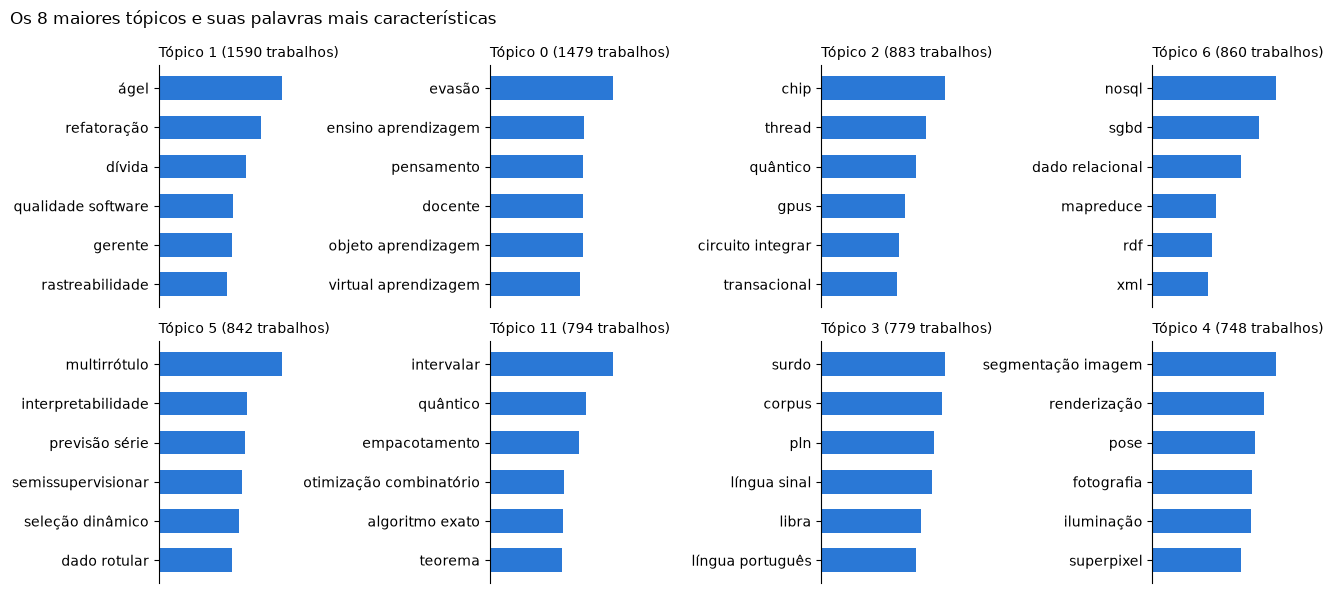

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, (_, linha) in zip(axes.flat, info.head(8).iterrows()):
    palavras = modelo.get_topic(linha["Topic"])[:6][::-1]
    ax.barh([p for p, _ in palavras], [peso for _, peso in palavras], color="#2a78d6", height=0.6)
    ax.set_title(f"Tópico {linha['Topic']} ({linha['Count']} trabalhos)", fontsize=10, loc="left")
    ax.set_xticks([])
    for lado in ("top", "right", "bottom"):
        ax.spines[lado].set_visible(False)
fig.suptitle("Os 8 maiores tópicos e suas palavras mais características", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURAS / "topicos_principais.png", bbox_inches="tight")

In [6]:
# Salva o tópico de cada trabalho, usado na análise temporal e no app
docs[["id", "ano", "grau", "regiao", "topico"]].to_csv(
    PROCESSADOS / "topicos_bertopic.csv.gz", index=False, compression="gzip")
tabela.to_csv(RELATORIOS / "topicos_bertopic.csv", index=False)

## Baseline: LDA

O LDA recebe a contagem de palavras de cada resumo (o `texto_lematizado`) e precisa saber o
número de tópicos de antemão. Para a comparação ser justa, usamos o mesmo número de tópicos que
o BERTopic encontrou.

`max_df=0.5` ignora palavras presentes em mais da metade dos resumos (como "dado" e "modelo"),
que apareceriam em todos os tópicos sem diferenciar nenhum.

In [7]:
contador = CountVectorizer(min_df=10, max_df=0.5)
matriz = contador.fit_transform(textos)
vocabulario = contador.get_feature_names_out()

lda = LatentDirichletAllocation(n_components=n_topicos, learning_method="online",
                                batch_size=1024, max_iter=10, random_state=SEMENTE, n_jobs=1)  # n_jobs=1: processos paralelos copiariam os dados na memória
lda.fit(matriz)

palavras_lda = [[vocabulario[i] for i in pesos.argsort()[::-1][:10]] for pesos in lda.components_]
pd.DataFrame({"palavras": [", ".join(p[:8]) for p in palavras_lda]}).head(10)

,palavras
0,"codificação, mercado, dado, banco, compressão, ativo, ação, tabela"
1,"usuário, interação, design, interface, usabilidade, experiência, artefato, protótipo"
2,"agente, ambiente, comportamento, virtual, humano, ação, inteligência, artificial"
3,"ecossistema, ator, smart, sustentável, arranjo, eixo, líquido, app"
4,"arquitetura, projeto, componente, módulo, software, hardware, embarcar, arquitetural"
5,"função, espaço, operador, representação, espacial, visualização, dimensão, similaridade"
6,"memória, desempenho, processamento, paralelo, execução, aplicação, computação, processador"
7,"colaborativo, colaboração, científico, registro, pesquisador, contrato, publicação, interoperabilidade"
8,"requisito, negócio, atividade, workflow, organização, especificação, informação, execução"
9,"veículo, cidade, urbano, transporte, inteligente, rota, trânsito, acidente"


## Comparação

As duas métricas são calculadas sobre as 10 palavras principais de cada tópico. No BERTopic,
os termos compostos ("rede neural") entram como as palavras separadas, para os dois modelos
serem medidos da mesma forma.

In [8]:
documentos = [set(t.split()) for t in textos]

def palavras_simples(lista, n=10):
    vistas = []
    for termo in lista:
        for palavra in termo.split():
            if palavra not in vistas:
                vistas.append(palavra)
    return vistas[:n]

palavras_bertopic = [palavras_simples([p for p, _ in modelo.get_topic(t)])
                     for t in info["Topic"]]

comparacao = pd.DataFrame({
    "modelo": ["BERTopic", "LDA"],
    "tópicos": [n_topicos, n_topicos],
    "coerência (NPMI)": [coerencia_npmi(palavras_bertopic, documentos),
                         coerencia_npmi(palavras_lda, documentos)],
    "diversidade": [diversidade(palavras_bertopic), diversidade(palavras_lda)],
}).round(3)
comparacao.to_csv(RELATORIOS / "comparacao_bertopic_lda.csv", index=False)
comparacao

,modelo,tópicos,coerência (NPMI),diversidade
0,BERTopic,65,0.168,0.815
1,LDA,65,0.066,0.797


**Como ler:** coerência maior indica tópicos cujas palavras aparecem juntas nos mesmos
resumos, ou seja, temas mais nítidos. Diversidade perto de 1 indica tópicos que não repetem as
mesmas palavras. A interpretação dos resultados e os próximos passos ficam no README.